# Clase 4 — Prophet: estacionalidad aditiva vs. multiplicativa

Datos: `Data/ventas_internet.csv` — **ventas por internet y por catálogo en EE. UU.** (Amazon, tiendas online, venta por correo), en **millones de dólares por mes**, de enero 1992 a agosto 2026. Fuente: Oficina del Censo de EE. UU., vía FRED (serie `MRTSSM4541USN`).

- **Aditiva** (por defecto): la temporada suma una **cantidad fija**.
- **Multiplicativa**: la temporada suma un **porcentaje**, así que crece con la tendencia.

> En el video se usa `airline_passengers.csv` (1949–1960) y `fbprophet`. Ese dataset es histórico y no se actualiza. Este es un dataset actual donde la diferencia se ve igual de clara.

## Paso 1: Importar y leer los datos

In [1]:
import pandas as pd
from prophet import Prophet                        # en el video: from fbprophet import Prophet
from prophet.plot import add_changepoints_to_plot
import matplotlib.pyplot as plt
%matplotlib inline

df = pd.read_csv('Data/ventas_internet.csv')
df.head()

,observation_date,MRTSSM4541USN
0,1992-01-01,2644
1,1992-02-01,2245
2,1992-03-01,2440
3,1992-04-01,2462
4,1992-05-01,2439


## Paso 2: Preparar el formato

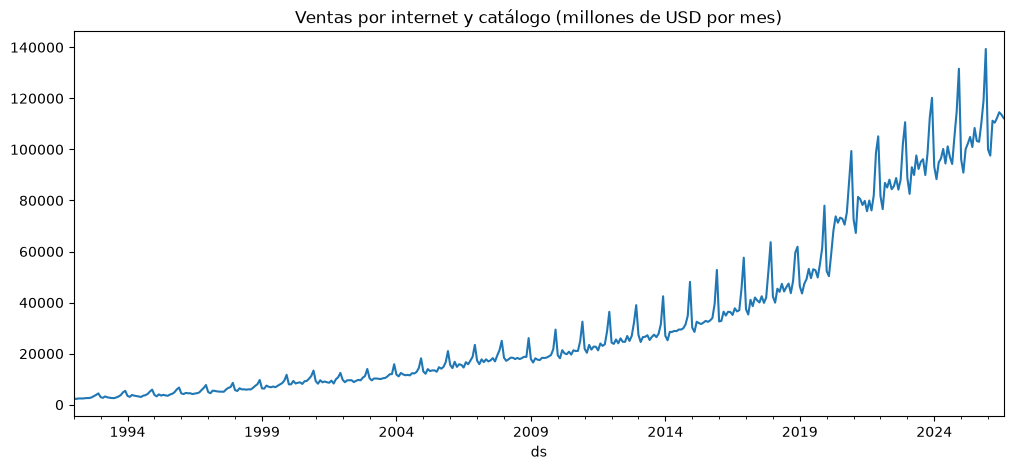

In [2]:
df.columns = ['ds', 'y']
df['ds'] = pd.to_datetime(df['ds'])
df.plot(x='ds', y='y', figsize=(12, 5), legend=False, title='Ventas por internet y catálogo (millones de USD por mes)');

## Paso 3: ¿Las olas crecen con el tiempo?

In [3]:
anual = df.groupby(df['ds'].dt.year)['y'].agg(['min', 'max', 'mean'])
anual = anual[df.groupby(df['ds'].dt.year).size() == 12]          # solo años completos
anual['ola'] = anual['max'] - anual['min']                         # tamaño de la ola (millones de USD)
anual['ola_%'] = (anual['ola'] / anual['mean'] * 100).round(1)     # tamaño de la ola (%)
anual.round(0)

,min,max,mean,ola,ola_%
ds,,,,,
1992,2245,4446,2882.0,2201,76.0
1993,2575,5446,3330.0,2871,86.0
1994,3041,5910,3849.0,2869,74.0
1995,3284,6717,4314.0,3433,80.0
1996,4154,7727,5007.0,3573,71.0
1997,4506,8568,5753.0,4062,71.0
1998,5382,9690,6606.0,4308,65.0
1999,6308,11722,7758.0,5414,70.0
2000,7988,13382,9374.0,5394,58.0


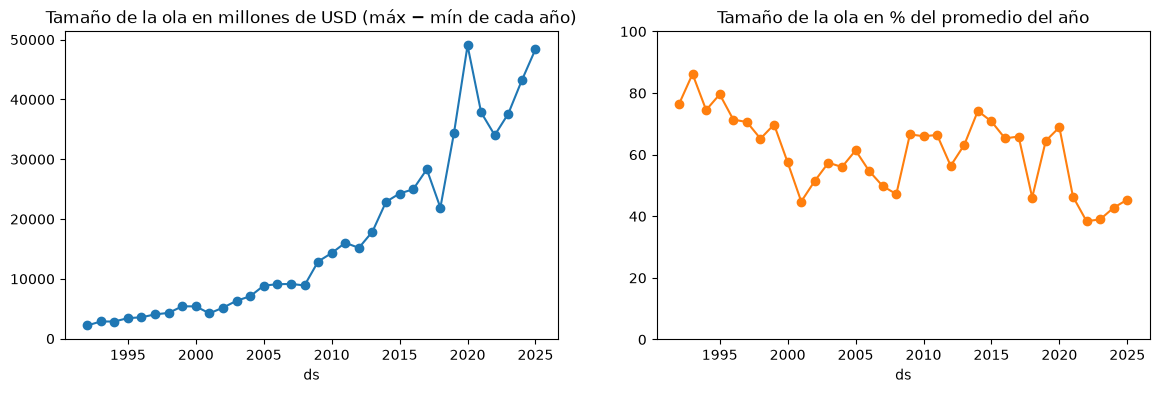

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
anual['ola'].plot(ax=axes[0], marker='o', title='Tamaño de la ola en millones de USD (máx − mín de cada año)')
anual['ola_%'].plot(ax=axes[1], marker='o', color='tab:orange', title='Tamaño de la ola en % del promedio del año')
axes[1].set_ylim(0, 100);

## Paso 4: Primer modelo — aditivo (el de siempre)

23:58:05 - cmdstanpy - INFO - Chain [1] start processing


23:58:05 - cmdstanpy - INFO - Chain [1] done processing


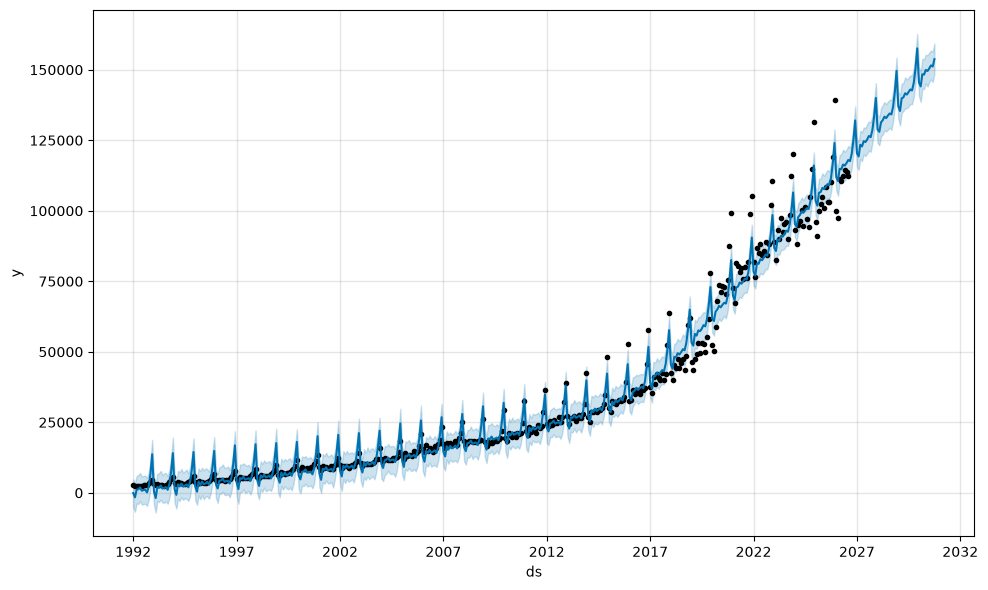

In [5]:
m = Prophet()
m.fit(df)
future = m.make_future_dataframe(50, freq='MS')
forecast = m.predict(future)
fig = m.plot(forecast)

## Paso 5: Las piezas del modelo aditivo

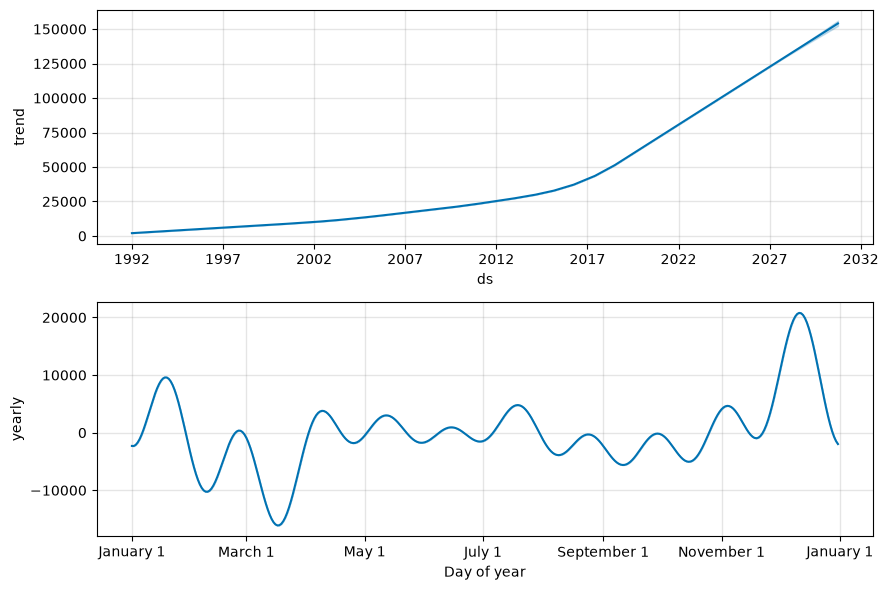

In [6]:
fig = m.plot_components(forecast);

## Paso 6: Los puntos de cambio

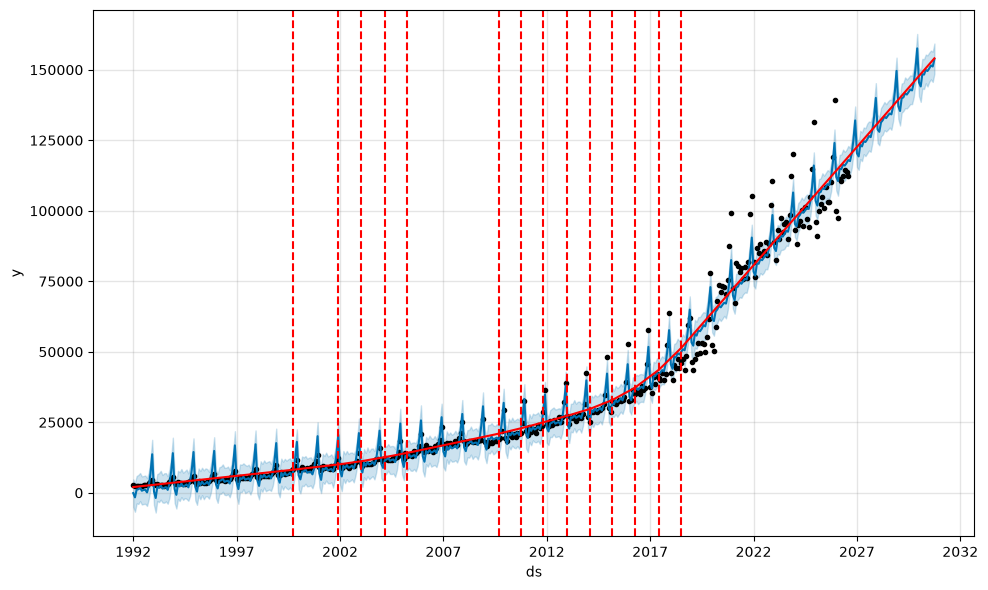

In [7]:
fig = m.plot(forecast)
a = add_changepoints_to_plot(fig.gca(), m, forecast)

## Paso 7: Segundo modelo — multiplicativo (lo nuevo de esta clase)

23:58:06 - cmdstanpy - INFO - Chain [1] start processing


23:58:06 - cmdstanpy - INFO - Chain [1] done processing


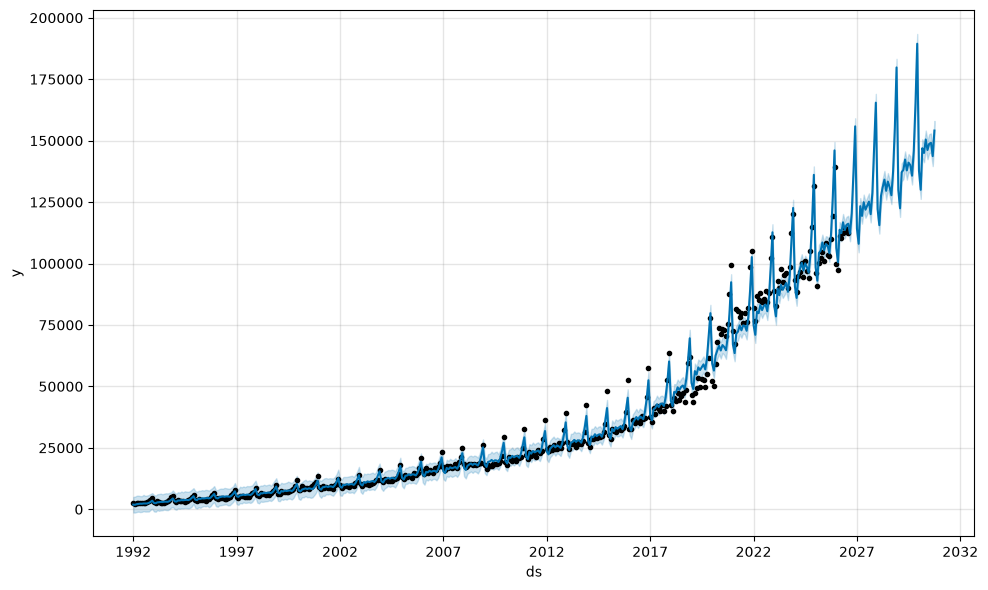

In [8]:
m = Prophet(seasonality_mode='multiplicative')
m.fit(df)
future = m.make_future_dataframe(50, freq='MS')
forecast = m.predict(future)
fig = m.plot(forecast)

## Paso 8: Las piezas del modelo multiplicativo

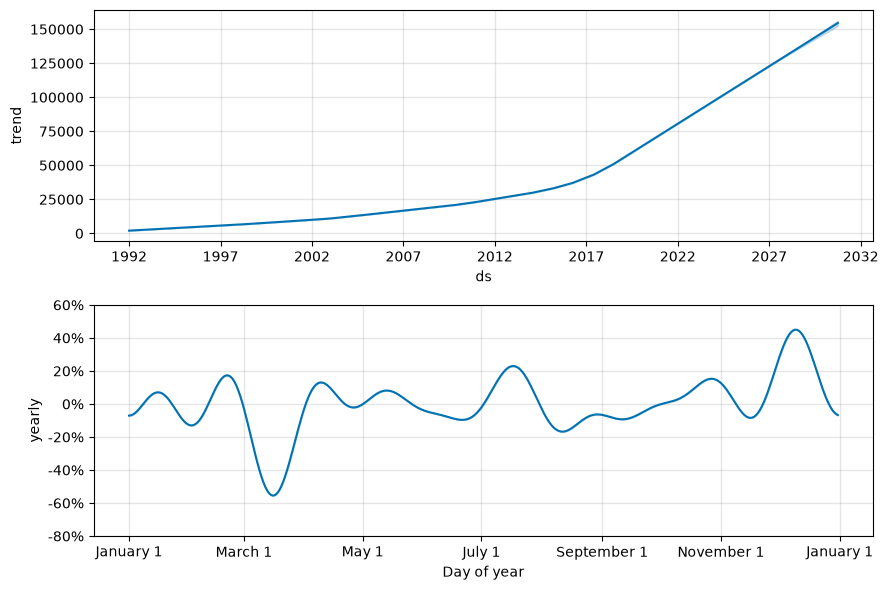

In [9]:
fig = m.plot_components(forecast);

## Paso 9 (extra): ¿Cuál es mejor? Que decida el RMSE

Lo que recomienda el profesor: probar los dos en datos de prueba y quedarse con el de menor RMSE.

In [10]:
from statsmodels.tools.eval_measures import rmse

train = df.iloc[:-12]     # todo menos el último año
test  = df.iloc[-12:]     # el último año (sep 2025 -> ago 2026)

resultados = {}
for modo in ['additive', 'multiplicative']:
    mod = Prophet(seasonality_mode=modo)
    mod.fit(train)
    fc = mod.predict(mod.make_future_dataframe(periods=12, freq='MS'))
    pred = fc.iloc[-12:]['yhat']
    resultados[modo] = {
        'RMSE': round(rmse(pred, test['y']), 0),
        'Error %': round(rmse(pred, test['y']) / test['y'].mean() * 100, 2),
    }

pd.DataFrame(resultados).T

23:58:07 - cmdstanpy - INFO - Chain [1] start processing


23:58:07 - cmdstanpy - INFO - Chain [1] done processing


23:58:07 - cmdstanpy - INFO - Chain [1] start processing


23:58:07 - cmdstanpy - INFO - Chain [1] done processing


,RMSE,Error %
additive,8847.0,7.90
multiplicative,6508.0,5.81


## Paso 10 (extra): Los dos modelos con zoom — años viejos vs. años recientes

23:58:07 - cmdstanpy - INFO - Chain [1] start processing


23:58:07 - cmdstanpy - INFO - Chain [1] done processing


23:58:07 - cmdstanpy - INFO - Chain [1] start processing


23:58:07 - cmdstanpy - INFO - Chain [1] done processing


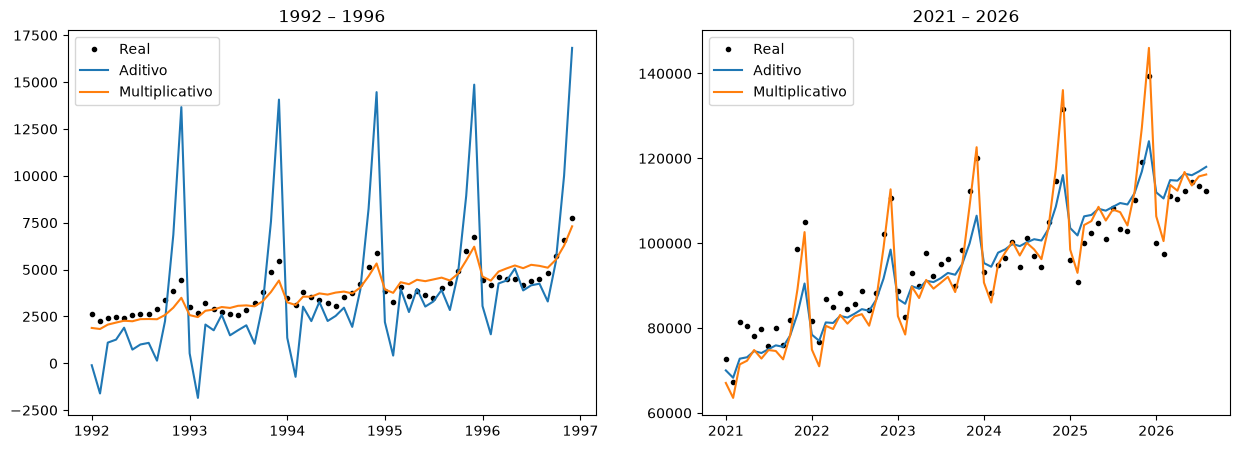

In [11]:
f_add = Prophet().fit(df).predict(df[['ds']])
f_mul = Prophet(seasonality_mode='multiplicative').fit(df).predict(df[['ds']])

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, (ini, fin) in zip(axes, [('1992-01-01', '1996-12-01'), ('2021-01-01', '2026-08-01')]):
    rango = (df['ds'] >= ini) & (df['ds'] <= fin)
    ax.plot(df.loc[rango, 'ds'], df.loc[rango, 'y'], 'k.', label='Real')
    ax.plot(f_add.loc[rango, 'ds'], f_add.loc[rango, 'yhat'], label='Aditivo')
    ax.plot(f_mul.loc[rango, 'ds'], f_mul.loc[rango, 'yhat'], label='Multiplicativo')
    ax.set_title(f'{ini[:4]} – {fin[:4]}')
    ax.legend()

## Paso 11 (extra): ¿Cuánto se equivoca cada modelo en cada época?

In [12]:
comp = df.copy()
comp['err_add_%'] = ((comp['y'] - f_add['yhat']).abs() / comp['y'] * 100)
comp['err_mul_%'] = ((comp['y'] - f_mul['yhat']).abs() / comp['y'] * 100)
comp['época'] = pd.cut(comp['ds'].dt.year, [1991, 1996, 2005, 2015, 2026],
                       labels=['1992-1996', '1997-2005', '2006-2015', '2016-2026'])
comp.groupby('época', observed=True)[['err_add_%', 'err_mul_%']].mean().round(1)

,err_add_%,err_mul_%
época,,
1992-1996,50.7,11.7
1997-2005,17.0,5.9
2006-2015,5.2,4.5
2016-2026,6.5,5.4


## Resumen

```python
m = Prophet()                                      # aditivo (por defecto)
m = Prophet(seasonality_mode='multiplicative')     # multiplicativo
```

Regla práctica: si las olas tienen siempre el mismo tamaño → aditivo. Si crecen con la tendencia → multiplicativo. Si dudas → prueba los dos y que decida el RMSE.